In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [2]:
file_name = "expenses.csv"

if os.path.exists(file_name):
    df = pd.read_csv(file_name)
else:
    df = pd.DataFrame(columns=[
        "Date", "Category", "Description", "Amount"
    ])

print("Expense Tracker Ready!")

Expense Tracker Ready!


In [3]:
df.head()

,Date,Category,Description,Amount


In [24]:
date = input("Enter Date (YYYY-MM-DD): ")

category = input("Enter Category: ")

description = input("Enter Description: ")

amount = float(input("Enter Amount: "))

new_expense = {
    "Date": date,
    "Category": category,
    "Description": description,
    "Amount": amount
}

print("\nExpense Details:")
print(new_expense)

Enter Date (YYYY-MM-DD):  2022-04-05
Enter Category:  servecing
Enter Description:  car
Enter Amount:  45000



Expense Details:
{'Date': '2022-04-05', 'Category': 'servecing', 'Description': 'car', 'Amount': 45000.0}


In [25]:
df = pd.concat(
    [df, pd.DataFrame([new_expense])],
    ignore_index=True
)

df.to_csv(file_name, index=False)

print("Expense Saved Successfully!")

Expense Saved Successfully!


In [26]:
print("----- ALL EXPENSES -----")
display(df)

----- ALL EXPENSES -----


,Date,Category,Description,Amount,Month
0,2026-06-12 00:00:00,Food,Lunch,500.0,2026-06
1,2024-06-02 00:00:00,Medicine,Fever,100.0,2024-06
2,2025-09-19 00:00:00,Traviling,Train_Trvl,5000.0,2025-09
3,2022-04-05,servecing,car,45000.0,NaT


In [27]:
print("----- ALL EXPENSES -----")
display(df)

----- ALL EXPENSES -----


,Date,Category,Description,Amount,Month
0,2026-06-12 00:00:00,Food,Lunch,500.0,2026-06
1,2024-06-02 00:00:00,Medicine,Fever,100.0,2024-06
2,2025-09-19 00:00:00,Traviling,Train_Trvl,5000.0,2025-09
3,2022-04-05,servecing,car,45000.0,NaT


In [28]:
category_expense = df.groupby("Category")["Amount"].sum()

print("----- CATEGORY WISE EXPENSE -----")
display(category_expense)

----- CATEGORY WISE EXPENSE -----


Category
Food           500.0
Medicine       100.0
Traviling     5000.0
servecing    45000.0
Name: Amount, dtype: object

In [29]:
search_category = input("Enter Category to Search: ")

result = df[df["Category"].str.lower() == search_category.lower()]

if len(result) > 0:
    print("----- SEARCH RESULTS -----")
    display(result)
else:
    print("No Expense Found!")

Enter Category to Search:  servecing


----- SEARCH RESULTS -----


,Date,Category,Description,Amount,Month
3,2022-04-05,servecing,car,45000.0,NaT


In [30]:
df["Date"] = pd.to_datetime(df["Date"])

df["Month"] = df["Date"].dt.to_period("M")

monthly_expense = df.groupby("Month")["Amount"].sum()

print("----- MONTHLY EXPENSE REPORT -----")
display(monthly_expense)

----- MONTHLY EXPENSE REPORT -----


Month
2022-04    45000.0
2024-06      100.0
2025-09     5000.0
2026-06      500.0
Freq: M, Name: Amount, dtype: object

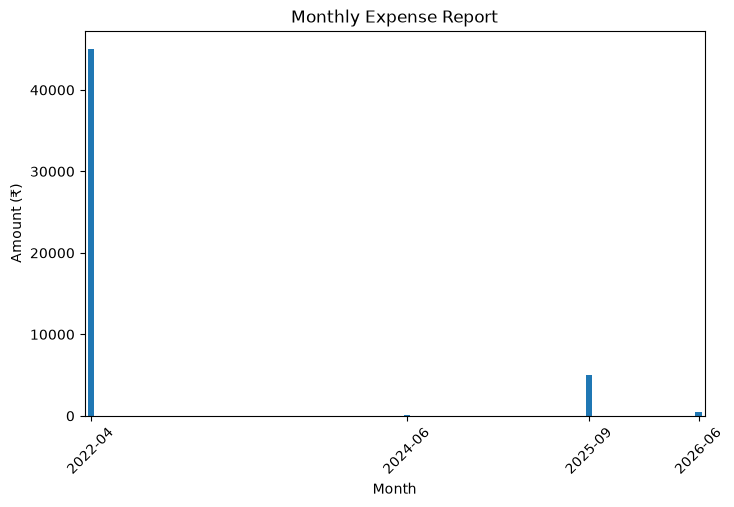

In [31]:
monthly_expense.plot(
    kind="bar",
    figsize=(8, 5),
    title="Monthly Expense Report"
)

plt.xlabel("Month")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)
plt.show()

In [33]:
def add_expense():

    date = input("Enter Date (YYYY-MM-DD): ")
    category = input("Enter Category: ")
    description = input("Enter Description: ")
    amount = float(input("Enter Amount: "))

    new_expense = {
        "Date": date,
        "Category": category,
        "Description": description,
        "Amount": amount
    }

    new_df = pd.DataFrame([new_expense])

    new_df.to_csv(file_name, mode="a", header=False, index=False)

    print("Expense Added Successfully!")

In [34]:
add_expense()

Enter Date (YYYY-MM-DD):  2023-05-15
Enter Category:  Travaling
Enter Description:  summary
Enter Amount:  60000


Expense Added Successfully!


In [35]:
df = pd.read_csv(file_name)

print("----- UPDATED EXPENSES -----")
display(df)

----- UPDATED EXPENSES -----


,Date,Category,Description,Amount,Month
0,2026-06-12 00:00:00,Food,Lunch,500.0,2026-06
1,2024-06-02 00:00:00,Medicine,Fever,100.0,2024-06
2,2025-09-19 00:00:00,Traviling,Train_Trvl,5000.0,2025-09
3,2022-04-05,servecing,car,45000.0,NaN
4,2023-05-15,Travaling,summary,60000.0,NaN


In [36]:
def delete_expense():

    global df

    display(df)

    row_no = int(input("Enter Row Index to Delete: "))

    if row_no in df.index:
        df = df.drop(row_no)
        df = df.reset_index(drop=True)

        df.to_csv(file_name, index=False)

        print("Expense Deleted Successfully!")
    else:
        print("Invalid Row Index!")

In [37]:
delete_expense()

,Date,Category,Description,Amount,Month
0,2026-06-12 00:00:00,Food,Lunch,500.0,2026-06
1,2024-06-02 00:00:00,Medicine,Fever,100.0,2024-06
2,2025-09-19 00:00:00,Traviling,Train_Trvl,5000.0,2025-09
3,2022-04-05,servecing,car,45000.0,NaN
4,2023-05-15,Travaling,summary,60000.0,NaN


Enter Row Index to Delete:  2


Expense Deleted Successfully!


In [ ]:
readme = """
# Expense Tracker using Python

## Project Description
This project is a simple Expense Tracker built using Python.
Users can add, view, search and delete expenses.

## Features
- Add New Expense
- View All Expenses
- Search Expenses by Category
- Delete Expenses
- Calculate Total Expenses
- Category-wise Expense Report
- Monthly Expense Report
- Monthly Expense Chart
- Save Data in CSV File

## Technologies Used
- Python
- Pandas
- Matplotlib
- CSV
- Jupyter Notebook

## How to Run
1. Install Python
2. Install required libraries
3. Open Jupyter Notebook
4. Run all cells one by one

## Data Storage
All expense records are stored in expenses.csv.

## Author
Data Science Learner
"""

with open("README.md", "w") as file:
    file.write(readme)

print("README.md Created Successfully!")